# M5 verisini tanıyalım

`data/raw/` altında 5 dosya var. Kısaca:

| Dosya | Ne var? | Boyut |
|---|---|---|
| `calendar.csv` | Her gün için tarih, hafta numarası, özel günler, SNAP günleri | 1.969 gün |
| `sales_train_evaluation.csv` | Her ürün-mağaza için **günlük satış adedi** (geniş format: her gün bir sütun) | 30.490 seri × 1.941 gün |
| `sales_train_validation.csv` | Aynısı, sadece son 28 gün eksik | 30.490 seri × 1.913 gün |
| `sell_prices.csv` | Ürünün mağazadaki **haftalık fiyatı** | 6,8 milyon satır |
| `sample_submission.csv` | Kaggle'a gönderilecek tahmin dosyasının şablonu | 60.980 satır |

Dosyalar birbirine şöyle bağlanıyor:

```
sales (d_1, d_2, ...)  --d-->  calendar  --wm_yr_wk-->  sell_prices (store_id + item_id)
```

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
pd.set_option("display.max_columns", 30)

## 1. `calendar.csv` — günler

Satış dosyasında tarih yok, sadece `d_1`, `d_2`, ... gibi gün kodları var. Bu dosya o kodları gerçek tarihe çeviriyor.

- `d`: gün kodu (satış dosyasındaki sütun adı)
- `wm_yr_wk`: Walmart hafta numarası → fiyat dosyasıyla bağlantı bunun üzerinden
- `event_name_1/2`, `event_type_1/2`: o gün özel bir gün var mı (Super Bowl, Ramazan, Christmas...)
- `snap_CA/TX/WI`: o eyalette gıda yardımı (SNAP) ödemesi yapılan gün mü (1/0)

In [3]:
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
print(calendar.shape)
print("Tarih aralığı:", calendar["date"].min().date(), "→", calendar["date"].max().date())
calendar.head()

(1969, 14)
Tarih aralığı: 2011-01-29 → 2016-06-19


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:
# Özel günler nelermiş?
calendar.dropna(subset=["event_name_1"])[["date", "event_name_1", "event_type_1"]].head(15)

In [4]:
calendar["event_type_1"].value_counts()

event_type_1
Religious    55
National     52
Cultural     37
Sporting     18
Name: count, dtype: int64

## 2. `sales_train_evaluation.csv` — günlük satışlar

Her satır bir **ürün × mağaza** serisi. İlk 6 sütun kimlik bilgisi, geri kalan 1.941 sütun her günün satış adedi.

- `id`: `FOODS_3_090_CA_1_evaluation` → ürün + mağaza + dosya türü
- `item_id`: ürün (`FOODS_3_090`)
- `dept_id`: departman (`FOODS_3`)
- `cat_id`: kategori (`FOODS`, `HOBBIES`, `HOUSEHOLD`)
- `store_id`: mağaza (`CA_1` ... `WI_3`, toplam 10 mağaza)
- `state_id`: eyalet (`CA`, `TX`, `WI`)

Dosya büyük (~120 MB), okuması birkaç saniye sürebilir.

In [5]:
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
print(sales.shape)
sales.iloc[:5, :12]  # ilk 6 kimlik sütunu + ilk 6 gün

(30490, 1947)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


In [6]:
# Hiyerarşi: kaç kategori, departman, mağaza var?
id_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales[id_cols].nunique()

item_id     3049
dept_id        7
cat_id         3
store_id      10
state_id       3
dtype: int64

In [7]:
# Hangi kategoride kaç seri var?
sales.groupby(["cat_id", "dept_id"]).size()

cat_id     dept_id    
FOODS      FOODS_1        2160
           FOODS_2        3980
           FOODS_3        8230
HOBBIES    HOBBIES_1      4160
           HOBBIES_2      1490
HOUSEHOLD  HOUSEHOLD_1    5320
           HOUSEHOLD_2    5150
dtype: int64

In [8]:
# Mağazalar ve eyaletler
sales.groupby(["state_id", "store_id"]).size()

state_id  store_id
CA        CA_1        3049
          CA_2        3049
          CA_3        3049
          CA_4        3049
TX        TX_1        3049
          TX_2        3049
          TX_3        3049
WI        WI_1        3049
          WI_2        3049
          WI_3        3049
dtype: int64

### Tek bir ürünün satışına bakalım

Geniş formattan bir satırı alıp gün sütunlarını tarih eksenine çeviriyoruz.

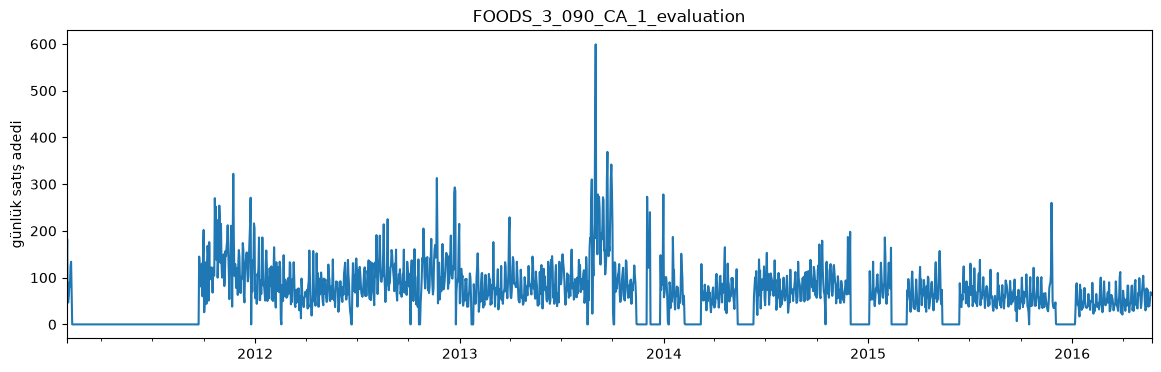

In [9]:
day_cols = [c for c in sales.columns if c.startswith("d_")]
d_to_date = calendar.set_index("d")["date"]

row = sales[sales["id"] == "FOODS_3_090_CA_1_evaluation"].iloc[0]
series = pd.Series(row[day_cols].values.astype(int), index=d_to_date[day_cols].values)

series.plot(figsize=(14, 4), title=row["id"])
plt.ylabel("günlük satış adedi")
plt.show()

In [10]:
# Satışların çoğu sıfır mı? (M5'in zorluğu bu)
zero_share = (sales[day_cols] == 0).mean().mean()
print(f"Tüm hücrelerin %{zero_share * 100:.1f}'i sıfır")

Tüm hücrelerin %68.0'i sıfır


## 3. `sales_train_validation.csv` — aynı dosyanın kısa hali

Yarışmanın ilk aşamasında yayınlanan versiyon. Son 28 gün (`d_1914`–`d_1941`) yok, onun dışında evaluation dosyasıyla aynı.
**Evaluation dosyasını kullanmak yeterli**, bunu açmaya gerek yok. Sadece farkı görmek için sütun adlarına bakalım:

In [11]:
val_cols = pd.read_csv(RAW / "sales_train_validation.csv", nrows=0).columns
print("validation son gün:", val_cols[-1], "| evaluation son gün:", sales.columns[-1])
print("Fark:", len(sales.columns) - len(val_cols), "gün")

validation son gün: d_1913 | evaluation son gün: d_1941
Fark: 28 gün


## 4. `sell_prices.csv` — haftalık fiyatlar

Her satır: bir mağazada bir ürünün bir haftadaki fiyatı.

- `store_id`, `item_id`: hangi mağaza, hangi ürün
- `wm_yr_wk`: hafta numarası (calendar'daki ile aynı)
- `sell_price`: fiyat (USD)

Ürün o hafta satışta değilse satır **yok**. Yani fiyatı olmayan haftalarda ürün henüz rafa girmemiş demektir.
Dosya 200 MB, okuması biraz sürer.

In [12]:
prices = pd.read_csv(RAW / "sell_prices.csv")
print(prices.shape)
prices.head()

(6841121, 4)


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


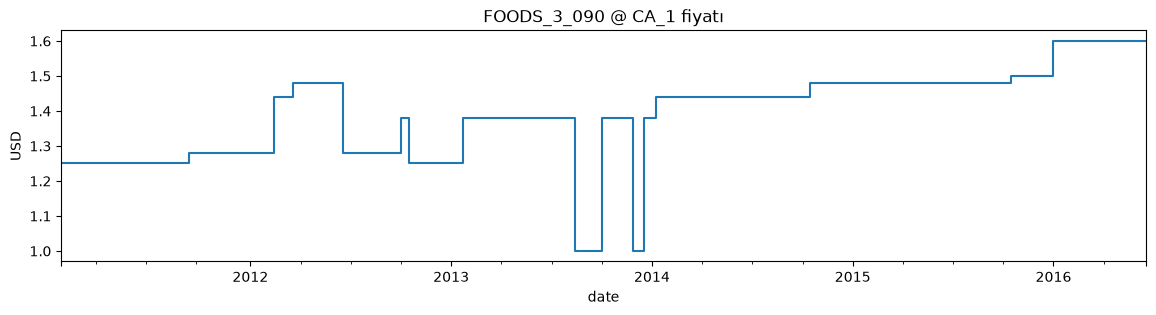

In [13]:
# Bir ürünün fiyatı zamanla nasıl değişmiş?
p = prices[(prices["store_id"] == "CA_1") & (prices["item_id"] == "FOODS_3_090")]
p = p.merge(calendar.drop_duplicates("wm_yr_wk")[["wm_yr_wk", "date"]], on="wm_yr_wk")

p.plot(x="date", y="sell_price", figsize=(14, 3), drawstyle="steps-post", legend=False,
       title="FOODS_3_090 @ CA_1 fiyatı")
plt.ylabel("USD")
plt.show()

## 5. `sample_submission.csv` — tahmin şablonu

Kaggle'a gönderilecek format: her seri için önümüzdeki **28 günün** tahmini (`F1`...`F28`).
Her seri iki kez geçiyor: `_validation` ve `_evaluation` satırları.

In [14]:
submission = pd.read_csv(RAW / "sample_submission.csv")
print(submission.shape)
submission.head()

(60980, 29)


,id,F1,F2,F3,F4,F5,F6,F7,F8,F9,F10,F11,F12,F13,F14,F15,F16,F17,F18,F19,F20,F21,F22,F23,F24,F25,F26,F27,F28
0,HOBBIES_1_001_CA_1_validation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 6. Bizim ürettiğimiz dosya: `data/processed/sales.parquet`

`src/prepare_data.py` yukarıdaki dosyaları birleştirip **uzun formata** çeviriyor:
sadece `CA_1` mağazası, `FOODS_3` departmanı, 2013-05-23 sonrası.
Her satır = bir ürünün bir günü. Model için kullanacağımız tablo bu.

In [15]:
df = pd.read_parquet(PROCESSED / "sales.parquet")
print(df.shape)
df.info()

(902008, 10)
<class 'pandas.DataFrame'>
RangeIndex: 902008 entries, 0 to 902007
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            902008 non-null  category      
 1   item_id       902008 non-null  category      
 2   store_id      902008 non-null  category      
 3   sales         902008 non-null  int16         
 4   date          902008 non-null  datetime64[us]
 5   wm_yr_wk      902008 non-null  int64         
 6   event_name_1  72424 non-null   category      
 7   event_type_1  72424 non-null   category      
 8   snap_CA       902008 non-null  int64         
 9   sell_price    846638 non-null  float64       
dtypes: category(5), datetime64[us](1), float64(1), int16(1), int64(2)
memory usage: 35.3 MB


In [16]:
df.head(10)

,id,item_id,store_id,sales,date,wm_yr_wk,event_name_1,event_type_1,snap_CA,sell_price
0,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-23,11317,NaN,NaN,0,2.5
1,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-24,11317,NaN,NaN,0,2.5
2,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-25,11318,NaN,NaN,0,2.5
3,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-26,11318,NaN,NaN,0,2.5
4,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-27,11318,MemorialDay,National,0,2.5
5,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-28,11318,NaN,NaN,0,2.5
6,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-29,11318,NaN,NaN,0,2.5
7,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-30,11318,NaN,NaN,0,2.5
8,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-05-31,11318,NaN,NaN,0,2.5
9,FOODS_3_001_CA_1_evaluation,FOODS_3_001,CA_1,0,2013-06-01,11319,NaN,NaN,1,2.5


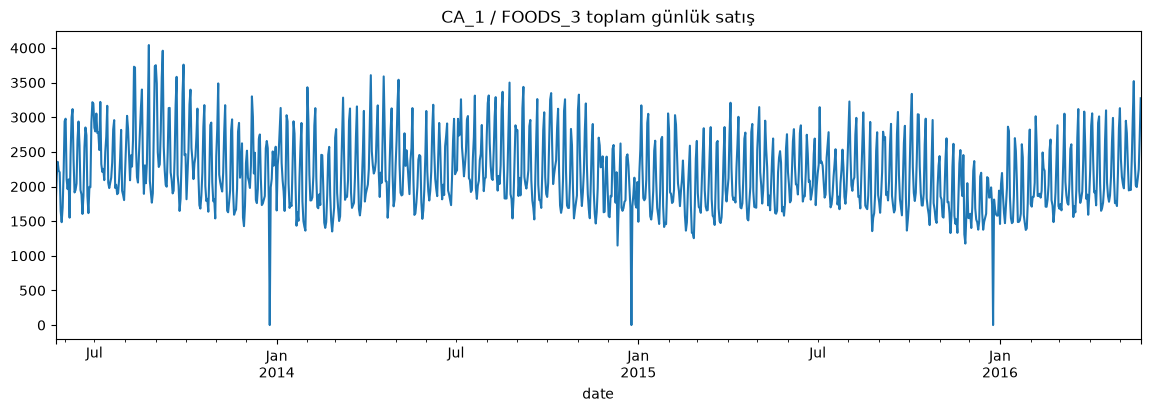

In [17]:
# Departmandaki toplam günlük satış
daily = df.groupby("date")["sales"].sum()
daily.plot(figsize=(14, 4), title="CA_1 / FOODS_3 toplam günlük satış")
plt.show()